In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- 1. Hàm tạo FSK ----------
def FSK(bit_seq, A=1, fs=10000, Tb=0.01, f0=100, f1=300):
    samples_per_bit = int(Tb * fs)
    t_bit = np.arange(0, Tb, 1/fs)
    signal = []
    for bit in bit_seq:
        freq = f1 if bit == 1 else f0
        carrier = A * np.cos(2 * np.pi * freq * t_bit)
        signal.append(carrier)
    return np.concatenate(signal)

# ---------- 2. Hàm thêm AWGN ----------
def add_awgn(signal, snr_db):
    Ps = np.mean(signal**2)
    snr_linear = 10**(snr_db/10)
    Pn = Ps / snr_linear
    sigma = np.sqrt(Pn)
    noise = sigma * np.random.randn(len(signal))
    return signal + noise

# ---------- 3. Hàm giải điều chế non-coherent ----------
def demod_FSK(rx_signal, fs=10000, Tb=0.01, f0=100, f1=300):
    samples_per_bit = int(Tb * fs)
    N_bits = len(rx_signal) // samples_per_bit
    rx_bits = []

    t_bit = np.arange(0, Tb, 1/fs)
    carrier0 = np.cos(2*np.pi*f0*t_bit)
    carrier1 = np.cos(2*np.pi*f1*t_bit)

    for i in range(N_bits):
        bit_chunk = rx_signal[i*samples_per_bit:(i+1)*samples_per_bit]

        # Năng lượng thực sự (sum of squares)
        E0 = np.sum((bit_chunk * carrier0)**2)
        E1 = np.sum((bit_chunk * carrier1)**2)

        rx_bits.append(1 if E1 > E0 else 0)
    return np.array(rx_bits)

# ---------- 4. Mô phỏng BER ----------
N_bits = 1000
bit_seq = np.random.randint(0,2,N_bits)
fs = 10000
Tb = 0.01
f0 = 100
f1 = 300

SNR_dB = np.arange(0,16,2)
BER = []

for snr in SNR_dB:
    tx_signal = FSK(bit_seq, fs=fs, Tb=Tb, f0=f0, f1=f1)
    rx_signal = add_awgn(tx_signal, snr)
    rx_bits = demod_FSK(rx_signal, fs=fs, Tb=Tb, f0=f0, f1=f1)
    ber = np.sum(bit_seq != rx_bits)/N_bits
    BER.append(ber)

# ---------- 5. Vẽ BER curve ----------
plt.semilogy(SNR_dB, BER, 'o-', linewidth=2)
plt.grid(True, which='both')
plt.xlabel("SNR (dB)")
plt.ylabel("BER")
plt.title("BER curve of Non-Coherent FSK")
plt.show()


QAM

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from QAM_modul import QAM, Rayleigh_fading, set_seed, binary_to_gray, gray_to_binary, ber_theory_16qam_awgn, compute_ber

set_seed(42)
N_bits = 1000000
EbN0_dB_range = np.arange(0, 31, 5)
bits_tx = np.random.randint(0, 2, N_bits)


M-QAM Coding

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


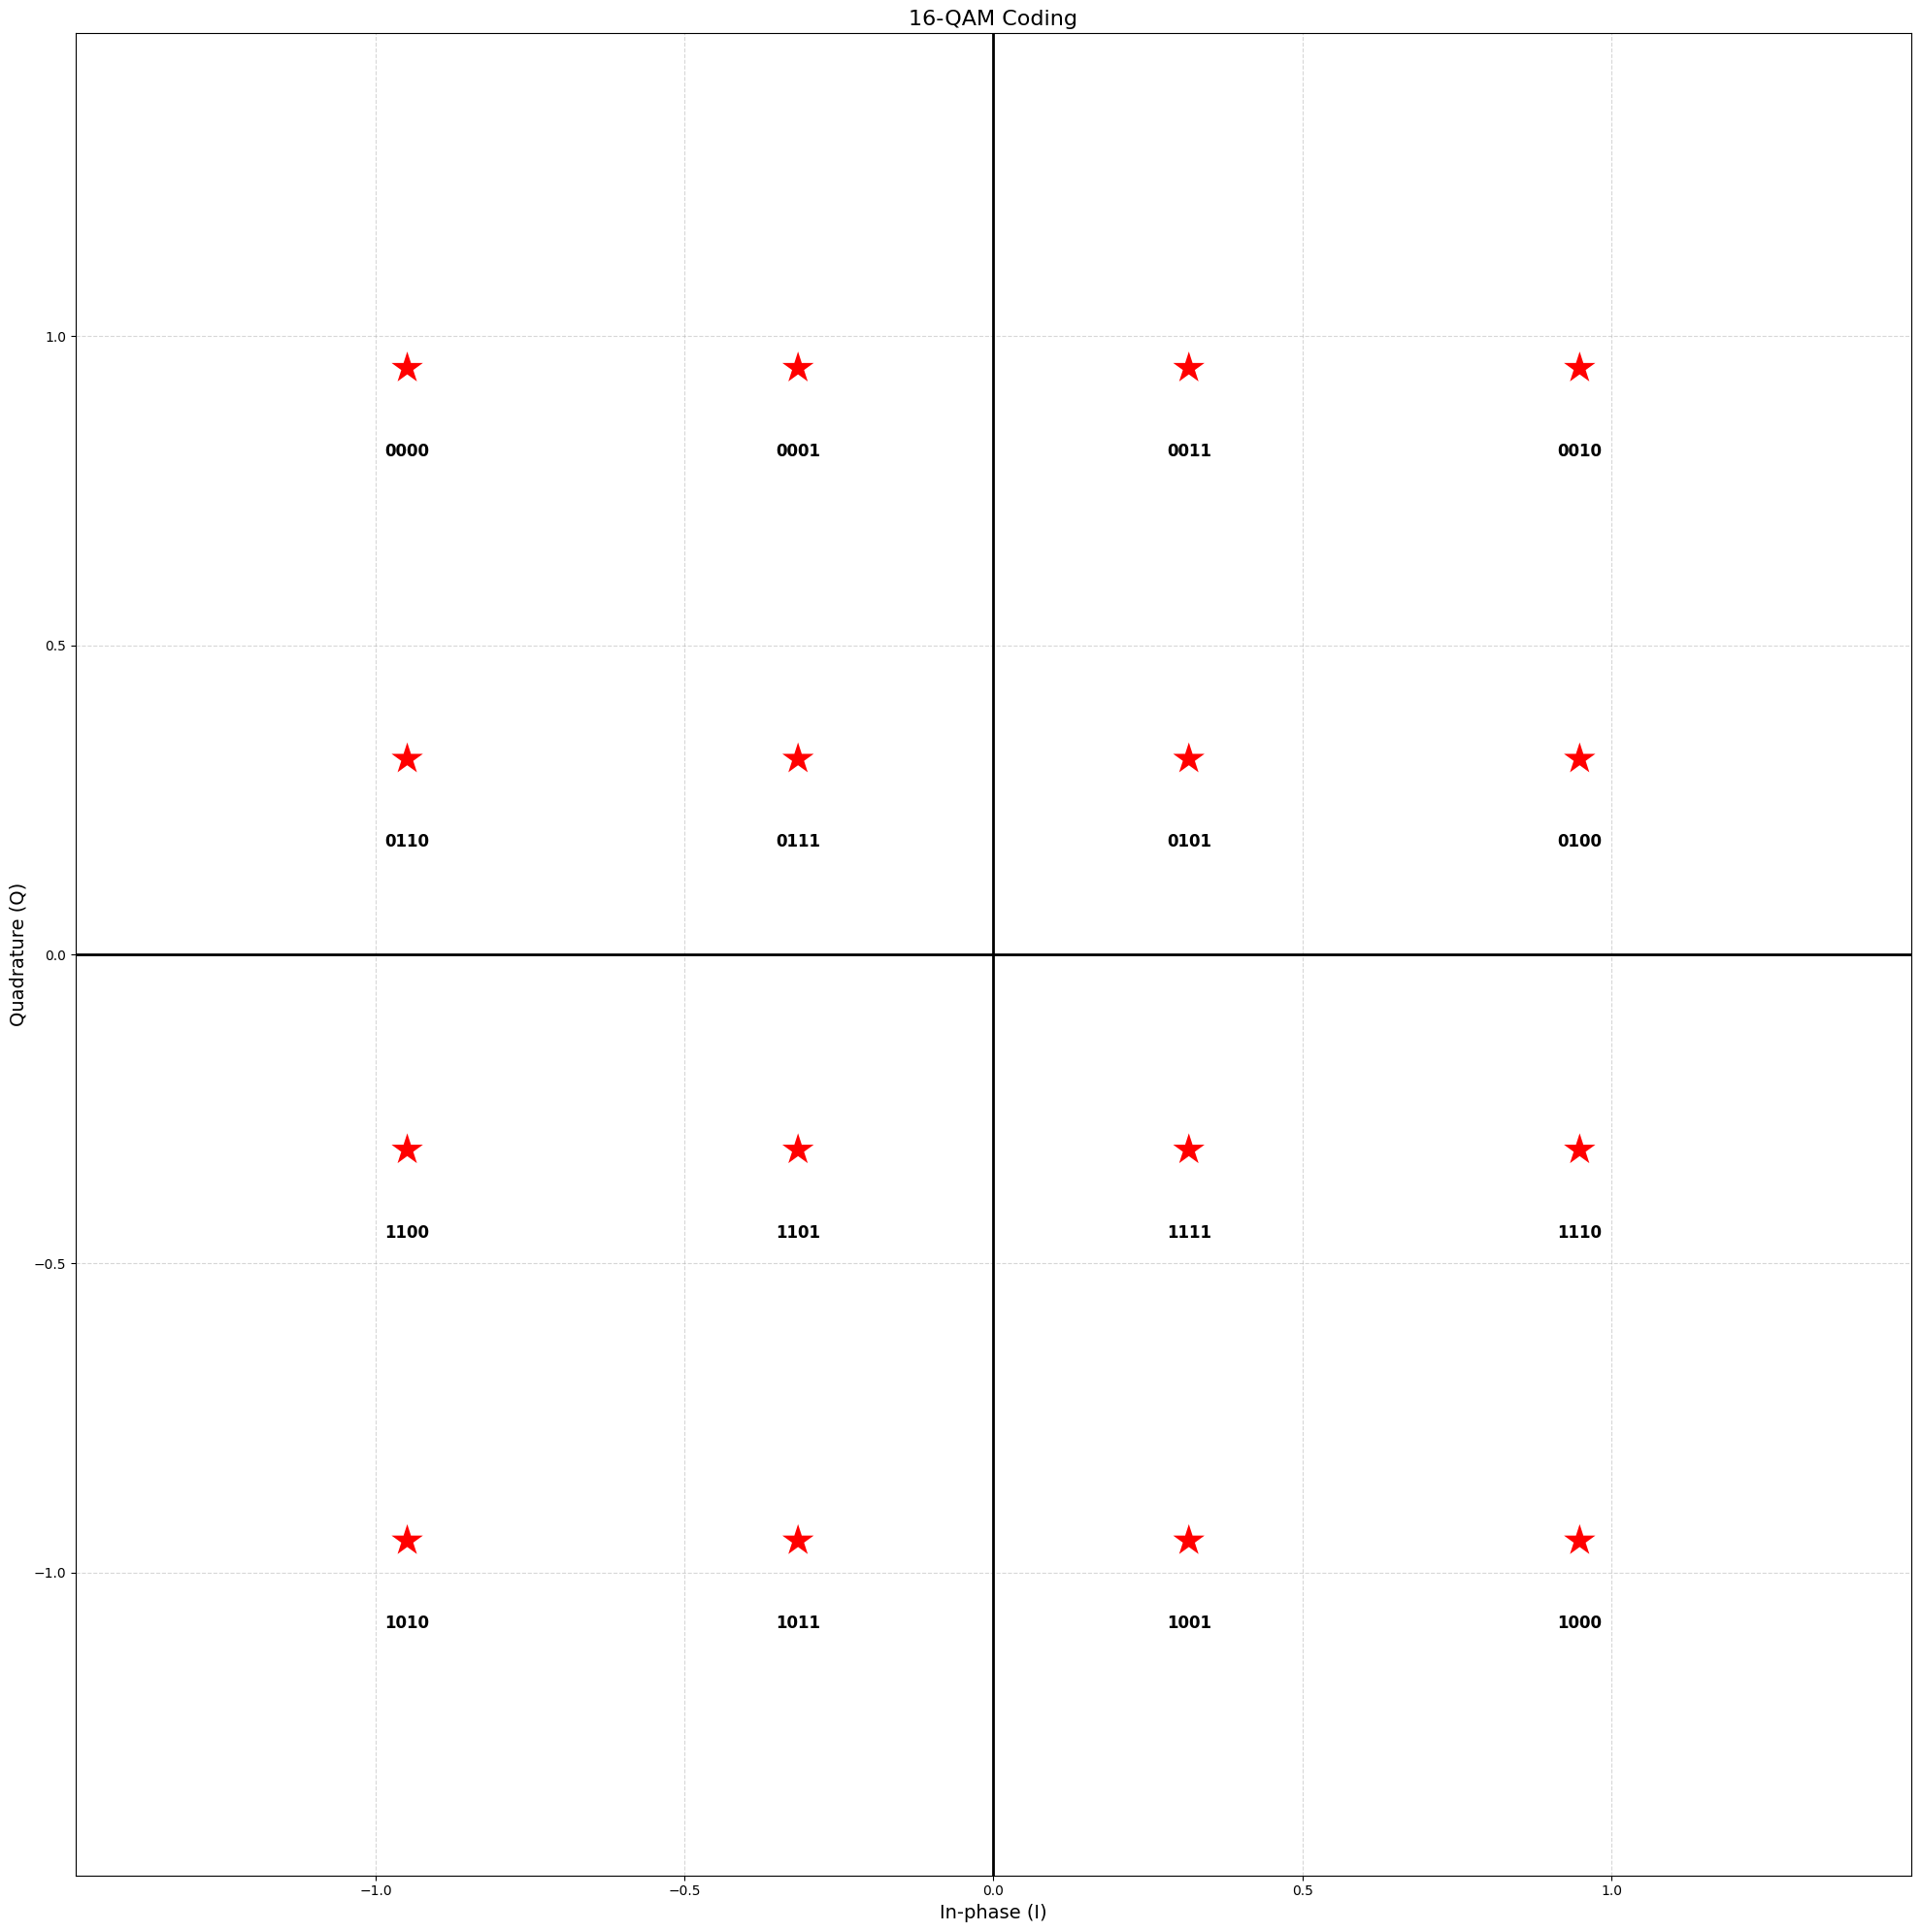

In [3]:
plt.figure(figsize=(20, 20))

M = 16

qam16 = QAM(M)
constellation = qam16.constellation
plt.scatter(np.real(constellation), np.imag(constellation), s=0, c='blue', marker='o')


ax = plt.gca()
ax.axhline(y=0, color='black', linewidth=2)
ax.axvline(x=0, color='black', linewidth=2)



for idx, symbol in enumerate(constellation):
    gray_code = binary_to_gray(idx)
    bit_string = np.binary_repr(gray_code, width=int(np.log2(M)))
    
    plt.scatter(np.real(symbol), np.imag(symbol), s=600, c='red', marker='*', edgecolors='none')
    
    plt.text(np.real(symbol), np.imag(symbol)-0.12, bit_string, ha='center', va='top', 
             fontsize=12, fontweight='bold', color='black')

plt.grid(True, linestyle='--', alpha=0.5)
plt.xlabel("In-phase (I)", fontsize=14)
plt.ylabel("Quadrature (Q)", fontsize=14)
plt.title(f"{M}-QAM Coding", fontsize=16)
plt.axis('equal')
plt.xlim(-1.5, 1.5)
plt.ylim(-1.5, 1.5)
plt.tight_layout()
plt.show()


BER M-QAM

In [10]:
ber_results = {}
M_list = [4, 16, 64, 256]
for M in M_list:
    qam = QAM(M)
    k = qam.k
    bits_tx_m = bits_tx[:len(bits_tx) - len(bits_tx) % k]
        
    ber_sim = []
    print(f"\n========== Simulating {M}-QAM ==========")
    for EbN0_dB in EbN0_dB_range:
        snr_db = EbN0_dB + 10*np.log10(k)  # convert Eb/N0 to SNR per symbol
        symbols = qam.bits_to_symbols(bits_tx_m)
        ber_per_channel = []
        
        for ch in range(2):

            y_eq = Rayleigh_fading(symbols, snr_db)  # mỗi lần gọi => kênh khác nhau
            bits_rx = qam.symbols_to_bits(y_eq)
            ber_per_channel.append(compute_ber(bits_tx_m, bits_rx))
        
        # trung bình BER qua tất cả kênh
        ber_avg = np.mean(ber_per_channel)
        ber_sim.append(ber_avg)
        
        print(f"Eb/N0={EbN0_dB} dB -> Avg BER={ber_avg:.6f}")

    ber_results[M] = ber_sim


========== Simulating 4-QAM ==========
Eb/N0=0 dB -> Avg BER=0.184723
Eb/N0=5 dB -> Avg BER=0.083043
Eb/N0=10 dB -> Avg BER=0.030595
Eb/N0=15 dB -> Avg BER=0.010114
Eb/N0=20 dB -> Avg BER=0.003225
Eb/N0=25 dB -> Avg BER=0.001057
Eb/N0=30 dB -> Avg BER=0.000325

========== Simulating 16-QAM ==========
Eb/N0=0 dB -> Avg BER=0.259709
Eb/N0=5 dB -> Avg BER=0.142529
Eb/N0=10 dB -> Avg BER=0.060201
Eb/N0=15 dB -> Avg BER=0.021401
Eb/N0=20 dB -> Avg BER=0.007075
Eb/N0=25 dB -> Avg BER=0.002141
Eb/N0=30 dB -> Avg BER=0.000700

========== Simulating 64-QAM ==========
Eb/N0=0 dB -> Avg BER=0.340960
Eb/N0=5 dB -> Avg BER=0.241157


KeyboardInterrupt: 

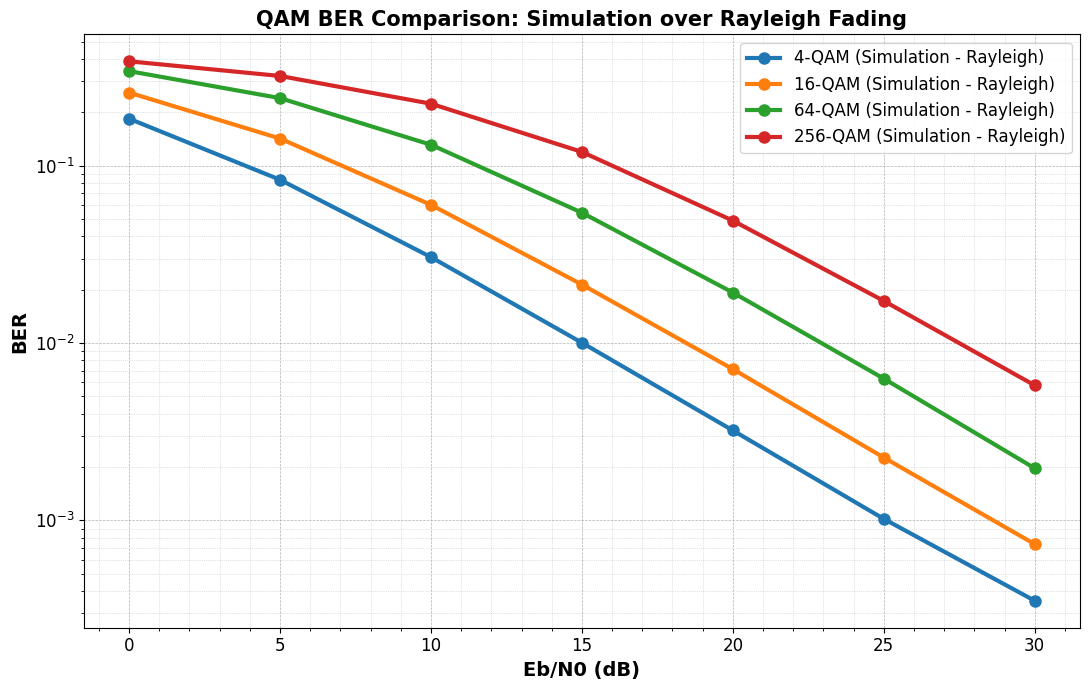

In [6]:
plt.figure(figsize=(11, 7))

for M in M_list:
    plt.semilogy(
        EbN0_dB_range, 
        ber_results[M], 
        linestyle='-', 
        linewidth=3, 
        marker='o', 
        markersize=8, 
        label=f'{M}-QAM (Simulation - Rayleigh)'
    )

plt.grid(True, which='both', linestyle='--', linewidth=0.5)

plt.xlabel("Eb/N0 (dB)", fontsize=14, fontweight='bold')
plt.ylabel("BER", fontsize=14, fontweight='bold')

plt.title("QAM BER Comparison: Simulation over Rayleigh Fading", 
          fontsize=15, fontweight='bold')

plt.legend(fontsize=12, loc='best')

plt.minorticks_on()
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.7)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.tight_layout()
plt.show()


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.



========== Bit Sequence ==========
Transmitted bits: [0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 1 1 1 0 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 0 1
 0 0 0 0 0 1 1 1 1 1 0 1 1 0 1 0 1 0 1 1 0 0 0 0 0 0 0]
Received bits:    [0 1 0 0 0 1 1 0 0 1 0 0 0 0 1 0 1 1 1 0 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 0 1
 0 0 0 0 0 1 1 1 1 1 0 1 1 0 1 0 1 0 1 1 0 0 0 0 0 0 0]
Bit Errors: 1 / 64


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


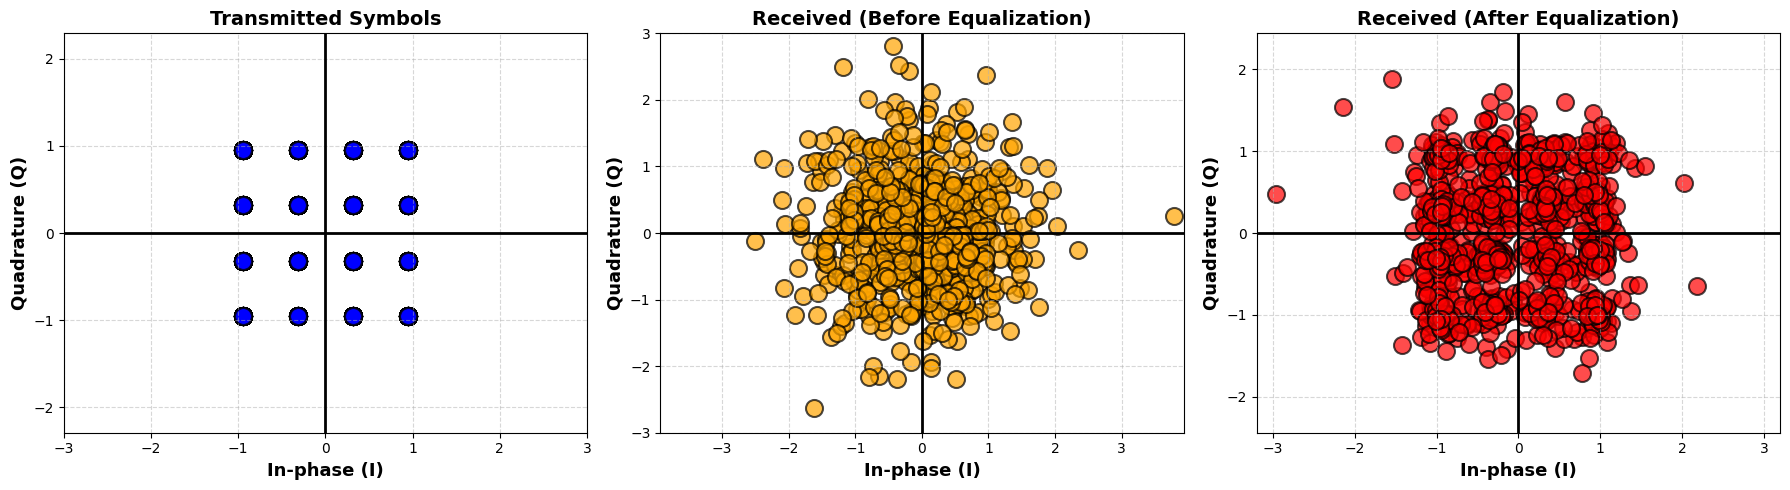

In [11]:
from QAM_modul import AWGN
M = 16
qam = QAM(M)
N_symbols = 1000  
EbN0_dB = 10

set_seed(42)
bits_tx = np.random.randint(0, 2, N_symbols * int(np.log2(M)))
bits_tx = bits_tx[:len(bits_tx) - len(bits_tx) % int(np.log2(M))]

print("\n========== Bit Sequence ==========")
print(f"Transmitted bits: {bits_tx[:64]}")

symbols_tx = qam.bits_to_symbols(bits_tx)

k = qam.k
snr_db = EbN0_dB + 10*np.log10(k)
h_real = np.random.normal(0, 1/np.sqrt(2), len(symbols_tx))
h_imag = np.random.normal(0, 1/np.sqrt(2), len(symbols_tx))
h = h_real + 1j*h_imag

symbols_faded = symbols_tx * h
symbols_noisy = AWGN(symbols_faded, snr_db)

symbols_rx = symbols_noisy / h

bits_rx = qam.symbols_to_bits(symbols_rx)
print(f"Received bits:    {bits_rx[:64]}")
print(f"Bit Errors: {np.sum(bits_tx[:64] != bits_rx[:64])} / 64")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ax = axes[0]
ax.scatter(np.real(symbols_tx), np.imag(symbols_tx), s=150, c='blue', alpha=0.7, edgecolors='black', linewidth=1.5)
ax.axhline(y=0, color='black', linewidth=2)
ax.axvline(x=0, color='black', linewidth=2)
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_xlabel("In-phase (I)", fontsize=13, fontweight='bold')
ax.set_ylabel("Quadrature (Q)", fontsize=13, fontweight='bold')
ax.set_title(f"Transmitted Symbols", fontsize=14, fontweight='bold')
ax.axis('equal')
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)

ax = axes[1]
ax.scatter(np.real(symbols_noisy), np.imag(symbols_noisy), s=150, c='orange', alpha=0.7, edgecolors='black', linewidth=1.5)
ax.axhline(y=0, color='black', linewidth=2)
ax.axvline(x=0, color='black', linewidth=2)
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_xlabel("In-phase (I)", fontsize=13, fontweight='bold')
ax.set_ylabel("Quadrature (Q)", fontsize=13, fontweight='bold')
ax.set_title(f"Received (Before Equalization)", fontsize=14, fontweight='bold')
ax.axis('equal')
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)

ax = axes[2]
ax.scatter(np.real(symbols_rx), np.imag(symbols_rx), s=150, c='red', alpha=0.7, edgecolors='black', linewidth=1.5)
ax.axhline(y=0, color='black', linewidth=2)
ax.axvline(x=0, color='black', linewidth=2)
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_xlabel("In-phase (I)", fontsize=13, fontweight='bold')
ax.set_ylabel("Quadrature (Q)", fontsize=13, fontweight='bold')
ax.set_title(f"Received (After Equalization)", fontsize=14, fontweight='bold')
ax.axis('equal')
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)

plt.tight_layout()
plt.show()

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


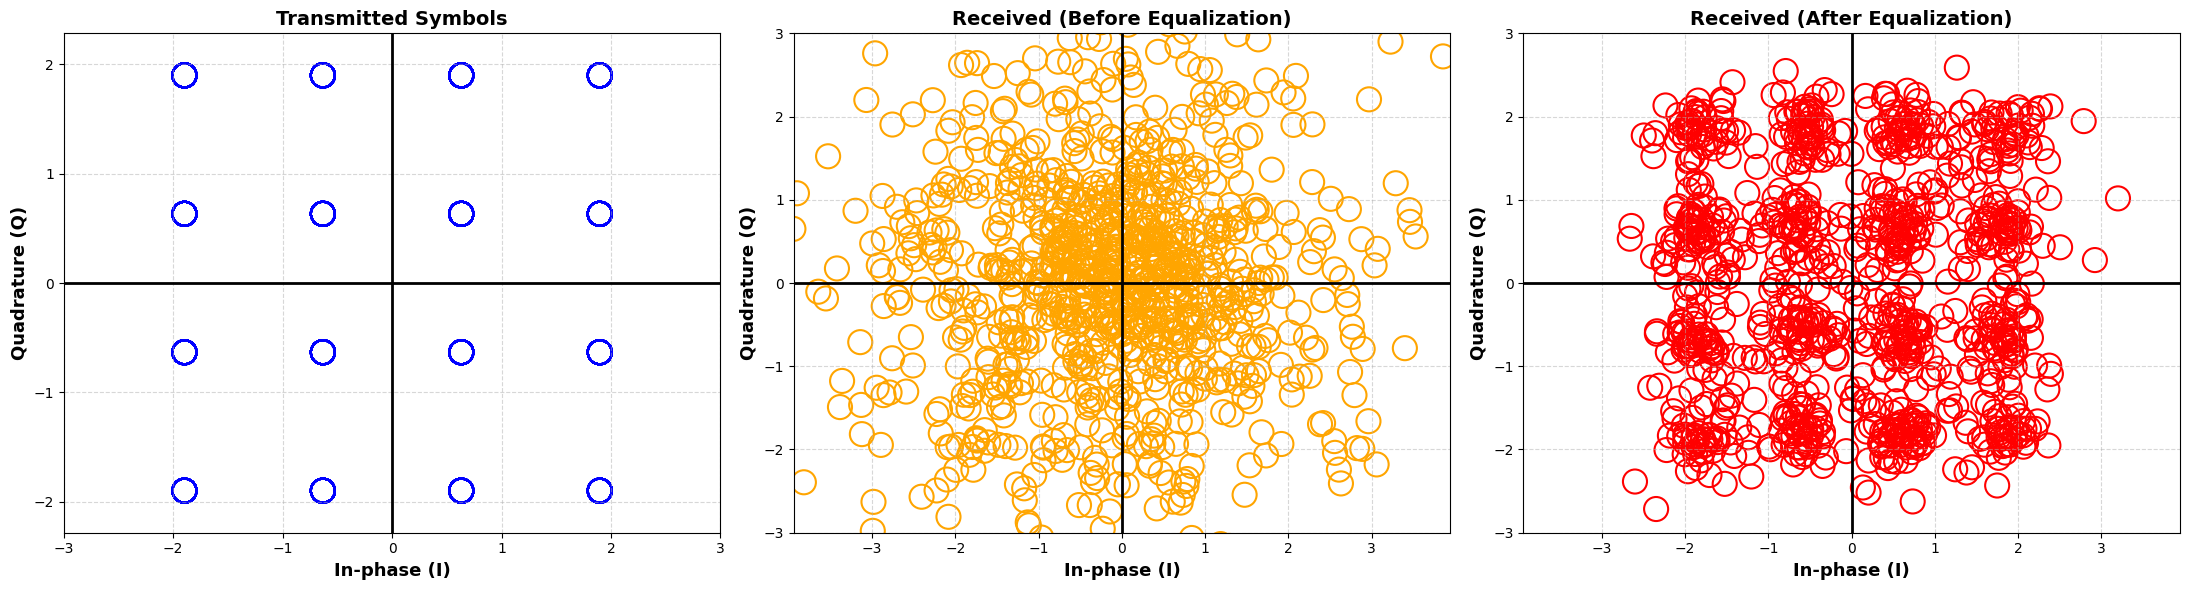

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from channel import QAM, AWGN

# ====================== Thiết lập ======================
M = 16
qam = QAM(M)
N_symbols = 1000
EbN0_dB = 10

np.random.seed(42)

# Sinh bit
bits_tx = np.random.randint(0, 2, N_symbols * int(np.log2(M)))
bits_tx = bits_tx[:len(bits_tx) - len(bits_tx) % int(np.log2(M))]

symbols_tx = qam.bits_to_symbols(bits_tx)

# ====================== Kênh Rayleigh + AWGN ======================
k = qam.k
snr_db = EbN0_dB + 10*np.log10(k)

h_real = np.random.normal(0, 1/np.sqrt(2), len(symbols_tx))
h_imag = np.random.normal(0, 1/np.sqrt(2), len(symbols_tx))
h = h_real + 1j*h_imag

symbols_faded = symbols_tx * h
symbols_noisy, N0 = AWGN(symbols_faded, snr_db)
symbols_rx = symbols_noisy * np.conj(h) / (np.abs(h)**2 + N0)

bits_rx = qam.symbols_to_bits(symbols_rx)

# ====================== Phóng to symbol ======================
scale = 2
symbols_tx_scaled = symbols_tx * scale
symbols_noisy_scaled = symbols_noisy * scale
symbols_rx_scaled = symbols_rx * scale

# ====================== Vẽ scatter plots (viền thôi) ======================
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

marker_size = 300
axis_limit = 3

titles = ['Transmitted Symbols', 'Received (Before Equalization)', 'Received (After Equalization)']
edge_colors = ['blue', 'orange', 'red']
symbol_sets = [symbols_tx_scaled, symbols_noisy_scaled, symbols_rx_scaled]

for ax, symbols, edgecolor, title in zip(axes, symbol_sets, edge_colors, titles):
    ax.scatter(np.real(symbols), np.imag(symbols), s=marker_size,
               facecolors='none', edgecolors=edgecolor, linewidth=1.5)
    ax.axhline(0, color='black', linewidth=2)
    ax.axvline(0, color='black', linewidth=2)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_xlabel("In-phase (I)", fontsize=13, fontweight='bold')
    ax.set_ylabel("Quadrature (Q)", fontsize=13, fontweight='bold')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.axis('equal')
    ax.set_xlim(-axis_limit, axis_limit)
    ax.set_ylim(-axis_limit, axis_limit)

plt.tight_layout()
plt.show()


--- [1/4] ĐANG KHỞI TẠO HỆ THỐNG ---
-> Suy hao FSPL: 205.15 dB
-> Tạp âm nền N: -141.61 dBW
--- [3/4] BẮT ĐẦU MÔ PHỎNG (K=10 dB) ---
   P_tx:  0 dBW | SNR:  -3.54 dB | BER Sim: 2.622500e-01
   P_tx:  2 dBW | SNR:  -1.54 dB | BER Sim: 2.103700e-01
   P_tx:  4 dBW | SNR:   0.46 dB | BER Sim: 1.579100e-01
   P_tx:  6 dBW | SNR:   2.46 dB | BER Sim: 1.059500e-01
   P_tx:  8 dBW | SNR:   4.46 dB | BER Sim: 6.122500e-02
   P_tx: 10 dBW | SNR:   6.46 dB | BER Sim: 2.977500e-02
   P_tx: 12 dBW | SNR:   8.46 dB | BER Sim: 1.156500e-02
   P_tx: 14 dBW | SNR:  10.46 dB | BER Sim: 3.675000e-03
   P_tx: 16 dBW | SNR:  12.46 dB | BER Sim: 1.045000e-03
   P_tx: 18 dBW | SNR:  14.46 dB | BER Sim: 2.150000e-04
   P_tx: 20 dBW | SNR:  16.46 dB | BER Sim: 4.000000e-05
   P_tx: 22 dBW | SNR:  18.46 dB | BER Sim: 3.000000e-05
   P_tx: 24 dBW | SNR:  20.46 dB | BER Sim: 0.000000e+00
   P_tx: 26 dBW | SNR:  22.46 dB | BER Sim: 0.000000e+00
   P_tx: 28 dBW | SNR:  24.46 dB | BER Sim: 0.000000e+00
   P_tx: 30

C:\Users\sang8\AppData\Local\Temp\ipykernel_3584\3794659213.py:74: RuntimeWarning: invalid value encountered in scalar multiply
  result = 2.0 * r * (K + 1.0) * np.exp(-K - (K + 1.0) * r * r) * i0(2.0 * r * np.sqrt(K * (K + 1.0)))


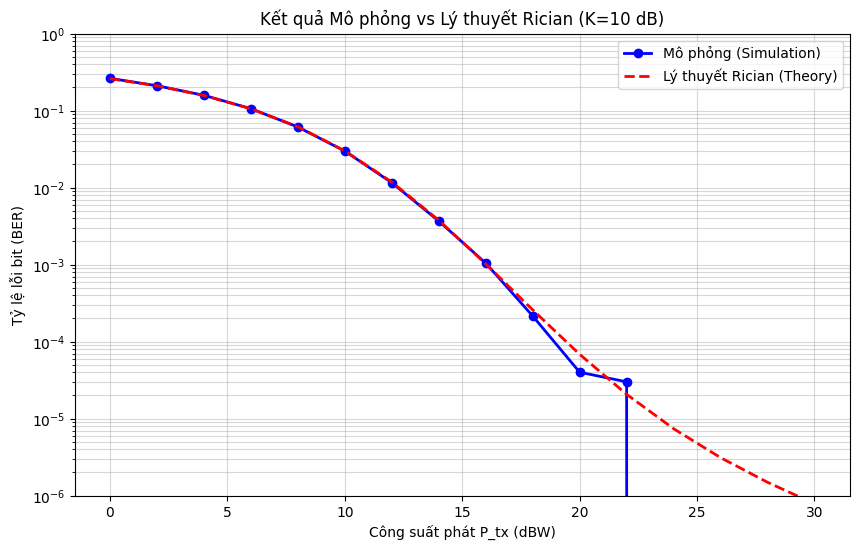

ĐÃ HOÀN THÀNH!


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os


# Thử import i0 an toàn (tương thích các phiên bản scipy)
try:
    from scipy.special import erfc, i0
except Exception:
    from scipy.special import erfc, iv
    i0 = lambda x: iv(0, x)


from scipy.integrate import quad
import traceback
import sys


# ==========================================
# PHẦN 1: CẤU HÌNH THÔNG SỐ (INPUT)
# ==========================================
print("--- [1/4] ĐANG KHỞI TẠO HỆ THỐNG ---")


fc = 12e9
d = 36000e3
c = 3e8
BW = 1e6
G_tx = 30
G_rx = 30
T_sys = 500
k_boltz = 1.38e-23


# Số bit (đảm bảo chẵn)
num_bits = 200000
if num_bits % 2 != 0:
    num_bits += 1


K_factor_dB = 10
P_tx_dBW_range = np.arange(0, 31, 2)


# ==========================================
# PHẦN 2: TÍNH TOÁN LINK BUDGET
# ==========================================
lamda = c / fc
FSPL_linear = (4 * np.pi * d / lamda) ** 2
FSPL_dB = 10 * np.log10(FSPL_linear)


N_noise_watts = k_boltz * T_sys * BW
N_noise_dBW = 10 * np.log10(N_noise_watts)


print(f"-> Suy hao FSPL: {FSPL_dB:.2f} dB")
print(f"-> Tạp âm nền N: {N_noise_dBW:.2f} dBW")


# ==========================================
# PHẦN 3: HÀM TÍNH BER LÝ THUYẾT RICIAN (CHUẨN XÁC)
# ==========================================
def calculate_rician_theory_exact(snr_db_list, K_db):
    print("--- [2/4] ĐANG TÍNH ĐƯỜNG LÝ THUYẾT (có thể mất vài giây)... ---")
    K = 10 ** (K_db / 10)
    ber_results = []


    def rician_pdf(r):
        if r < 0:
            return 0.0
        try:
            result = 2.0 * r * (K + 1.0) * np.exp(-K - (K + 1.0) * r * r) * i0(2.0 * r * np.sqrt(K * (K + 1.0)))
            return result if np.isfinite(result) else 0.0
        except:
            return 0.0


    for idx, snr_val_db in enumerate(snr_db_list):
        snr_linear = 10 ** (snr_val_db / 10)
        if snr_linear <= 0:
            ber_results.append(0.5)
            continue


        try:
            integrand = lambda r: 0.5 * erfc(np.sqrt(snr_linear / 2.0) * r) * rician_pdf(r)
            val, err = quad(integrand, 0, np.inf, epsabs=1e-10, epsrel=1e-8, limit=300)
            
            # Đảm bảo BER hợp lệ
            if np.isfinite(val) and 0 <= val <= 1:
                ber_results.append(val)
                print(f"   SNR: {snr_val_db:6.2f} dB | BER Theory: {val:.6e}")
            else:
                ber_results.append(0.5)
                print(f"   SNR: {snr_val_db:6.2f} dB | BER Theory: INVALID -> set to 0.5")
        except Exception as e:
            print(f"   SNR: {snr_val_db:6.2f} dB | Error calculating theory: {e}")
            ber_results.append(0.5)


    return ber_results


# ==========================================
# PHẦN 4: VÒNG LẶP MÔ PHỎNG (MONTE CARLO)
# ==========================================
def run_simulation():
    print(f"--- [3/4] BẮT ĐẦU MÔ PHỎNG (K={K_factor_dB} dB) ---")
    sim_ber = []


    EPS = 1e-12


    for P_tx in P_tx_dBW_range:
        P_rx = P_tx + G_tx + G_rx - FSPL_dB
        SNR_dB = P_rx - N_noise_dBW
        SNR_linear = 10 ** (SNR_dB / 10)


        if SNR_linear <= 0:
            SNR_linear = 1e-12


        bits = np.random.randint(0, 2, num_bits)
        symbols_tx = (2 * bits[0::2] - 1) + 1j * (2 * bits[1::2] - 1)
        symbols_tx = symbols_tx / np.sqrt(2)


        num_symbols = len(symbols_tx)
        K = 10 ** (K_factor_dB / 10)
        mu = np.sqrt(K / (K + 1))
        sigma = np.sqrt(1.0 / (2.0 * (K + 1.0)))


        h = mu + sigma * (np.random.randn(num_symbols) + 1j * np.random.randn(num_symbols))
        y_faded = h * symbols_tx


        noise_power = 1.0 / SNR_linear
        noise = np.sqrt(noise_power / 2.0) * (np.random.randn(num_symbols) + 1j * np.random.randn(num_symbols))
        y_received = y_faded + noise


        h_safe = np.where(np.abs(h) < EPS, EPS, h)
        y_equalized = y_received / h_safe


        bits_rx = np.zeros(num_bits, dtype=int)
        bits_rx[0::2] = (np.real(y_equalized) > 0).astype(int)
        bits_rx[1::2] = (np.imag(y_equalized) > 0).astype(int)


        ber = np.sum(bits != bits_rx) / num_bits
        sim_ber.append(ber)
        print(f"   P_tx: {P_tx:2d} dBW | SNR: {SNR_dB:6.2f} dB | BER Sim: {ber:.6e}")


    return sim_ber


# ==========================================
# PHẦN 5: VẼ ĐỒ THỊ
# ==========================================
def plot_results(sim_ber):
    print("--- [4/4] ĐANG TÍNH LÝ THUYẾT VÀ VẼ ĐỒ THỊ ---")
    SNR_range_theory = P_tx_dBW_range + G_tx + G_rx - FSPL_dB - N_noise_dBW
    theory_rician = calculate_rician_theory_exact(SNR_range_theory, K_factor_dB)


    plt.figure(figsize=(10, 6))
    plt.semilogy(P_tx_dBW_range, sim_ber, 'bo-', markersize=6, linewidth=2, label='Mô phỏng (Simulation)')
    plt.semilogy(P_tx_dBW_range, theory_rician, 'r--', linewidth=2, label='Lý thuyết Rician (Theory)')
    plt.grid(True, which="both", ls="-", alpha=0.5)
    plt.xlabel('Công suất phát P_tx (dBW)')
    plt.ylabel('Tỷ lệ lỗi bit (BER)')
    plt.title(f'Kết quả Mô phỏng vs Lý thuyết Rician (K={K_factor_dB} dB)')
    plt.legend()
    plt.ylim(1e-6, 1)


    try:
        plt.show()
    except Exception:
        out_path = os.path.join(os.getcwd(), 'ber_plot.png')
        plt.savefig(out_path)
        print(f"Không hiển thị được cửa sổ đồ thị, đã lưu sang: {out_path}")


def main():
    sim_ber = run_simulation()
    plot_results(sim_ber)
    print("ĐÃ HOÀN THÀNH!")


if __name__ == "__main__":
    try:
        main()
    except Exception:
        # Ghi traceback vào file để bạn gửi cho tôi nếu cần debug thêm
        tb_path = os.path.join(os.getcwd(), "racian_error.log")
        with open(tb_path, "w", encoding="utf-8") as f:
            traceback.print_exc(file=f)
        traceback.print_exc()
        print(f"Đã ghi traceback vào: {tb_path}")
        sys.exit(1)


--- [1/4] ĐANG KHỞI TẠO HỆ THỐNG ---
-> Suy hao FSPL: 205.15 dB
-> Tạp âm nền N: -141.61 dBW
--- [3/4] BẮT ĐẦU MÔ PHỎNG (K=10 dB) ---
   P_tx:  0 dBW | SNR:  -3.54 dB | BER Sim: 2.596625e-01
   P_tx:  2 dBW | SNR:  -1.54 dB | BER Sim: 2.100218e-01
   P_tx:  4 dBW | SNR:   0.46 dB | BER Sim: 1.571225e-01
   P_tx:  6 dBW | SNR:   2.46 dB | BER Sim: 1.056646e-01
   P_tx:  8 dBW | SNR:   4.46 dB | BER Sim: 6.162931e-02
   P_tx: 10 dBW | SNR:   6.46 dB | BER Sim: 2.993896e-02
   P_tx: 12 dBW | SNR:   8.46 dB | BER Sim: 1.182644e-02
   P_tx: 14 dBW | SNR:  10.46 dB | BER Sim: 3.776550e-03
   P_tx: 16 dBW | SNR:  12.46 dB | BER Sim: 1.019520e-03
   P_tx: 18 dBW | SNR:  14.46 dB | BER Sim: 2.581200e-04
   P_tx: 20 dBW | SNR:  16.46 dB | BER Sim: 6.796000e-05
   P_tx: 22 dBW | SNR:  18.46 dB | BER Sim: 2.063000e-05
   P_tx: 24 dBW | SNR:  20.46 dB | BER Sim: 7.210000e-06
   P_tx: 26 dBW | SNR:  22.46 dB | BER Sim: 3.080000e-06
   P_tx: 28 dBW | SNR:  24.46 dB | BER Sim: 1.500000e-06
   P_tx: 30

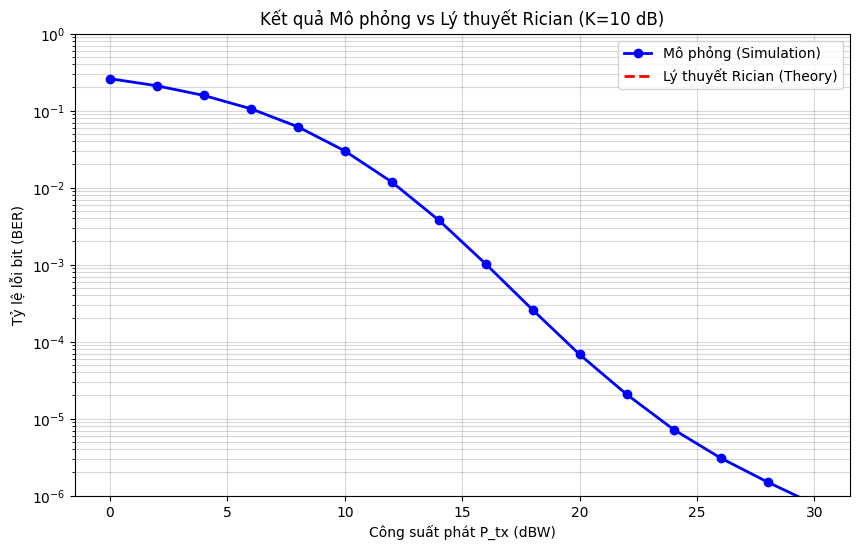

ĐÃ HOÀN THÀNH!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os


# Thử import i0 an toàn (tương thích các phiên bản scipy)
try:
    from scipy.special import erfc, i0
except Exception:
    from scipy.special import erfc, iv
    i0 = lambda x: iv(0, x)


from scipy.integrate import quad
import traceback
import sys


# ==========================================
# PHẦN 1: CẤU HÌNH THÔNG SỐ (INPUT)
# ==========================================
print("--- [1/4] ĐANG KHỞI TẠO HỆ THỐNG ---")


fc = 12e9
d = 36000e3
c = 3e8
BW = 1e6
G_tx = 30
G_rx = 30
T_sys = 500
k_boltz = 1.38e-23


# Số bit (đảm bảo chẵn)
num_bits = int(1e8)
if num_bits % 2 != 0:
    num_bits += 1


K_factor_dB = 10
P_tx_dBW_range = np.arange(0, 31, 2)


# ==========================================
# PHẦN 2: TÍNH TOÁN LINK BUDGET
# ==========================================
lamda = c / fc
FSPL_linear = (4 * np.pi * d / lamda) ** 2
FSPL_dB = 10 * np.log10(FSPL_linear)


N_noise_watts = k_boltz * T_sys * BW
N_noise_dBW = 10 * np.log10(N_noise_watts)


print(f"-> Suy hao FSPL: {FSPL_dB:.2f} dB")
print(f"-> Tạp âm nền N: {N_noise_dBW:.2f} dBW")


# ==========================================
PHẦN 3: HÀM TÍNH BER LÝ THUYẾT RICIAN (CHUẨN XÁC)
==========================================
def calculate_rician_theory_exact(snr_db_list, K_db):
    print("--- [2/4] ĐANG TÍNH ĐƯỜNG LÝ THUYẾT (có thể mất vài giây)... ---")
    K = 10 ** (K_db / 10)
    ber_results = []


    def rician_pdf(r):
        if r < 0:
            return 0.0
        try:
            result = 2.0 * r * (K + 1.0) * np.exp(-K - (K + 1.0) * r * r) * i0(2.0 * r * np.sqrt(K * (K + 1.0)))
            return result if np.isfinite(result) else 0.0
        except:
            return 0.0


    for idx, snr_val_db in enumerate(snr_db_list):
        snr_linear = 10 ** (snr_val_db / 10)
        if snr_linear <= 0:
            ber_results.append(0.5)
            continue


        try:
            integrand = lambda r: 0.5 * erfc(np.sqrt(snr_linear / 2.0) * r) * rician_pdf(r)
            val, err = quad(integrand, 0, np.inf, epsabs=1e-10, epsrel=1e-8, limit=300)
            
            # Đảm bảo BER hợp lệ
            if np.isfinite(val) and 0 <= val <= 1:
                ber_results.append(val)
                print(f"   SNR: {snr_val_db:6.2f} dB | BER Theory: {val:.6e}")
            else:
                ber_results.append(0.5)
                print(f"   SNR: {snr_val_db:6.2f} dB | BER Theory: INVALID -> set to 0.5")
        except Exception as e:
            print(f"   SNR: {snr_val_db:6.2f} dB | Error calculating theory: {e}")
            ber_results.append(0.5)


    return ber_results

def calculate_rician_qpsk_theory(snr_db_list, K_db):
    print("--- [2/4] ĐANG TÍNH BER LÝ THUYẾT QPSK RICIAN ---")

    K = 10 ** (K_db / 10)
    ber_results = []

    for snr_db in snr_db_list:
        gamma = 10 ** (snr_db / 10)   # Eb/N0 tuyến tính

        # ==== Công thức BER QPSK trung bình trên kênh Rician ====
        A = (1 + K) * gamma
        sqrt_term = np.sqrt(A / (1 + A))
        exp_term = np.exp(-K * (1 - 1 / (1 + A)))

        ber = 0.5 * (1 - sqrt_term * exp_term)
        # ==========================================================

        # Giới hạn BER hợp lệ
        if ber < 0: ber = 0.0
        if ber > 1: ber = 1.0

        ber_results.append(ber)
        print(f"   SNR: {snr_db:6.2f} dB | BER Theory (QPSK Rician): {ber:.6e}")

    return ber_results


# ==========================================
# PHẦN 4: VÒNG LẶP MÔ PHỎNG (MONTE CARLO)
# ==========================================
def run_simulation():
    print(f"--- [3/4] BẮT ĐẦU MÔ PHỎNG (K={K_factor_dB} dB) ---")
    sim_ber = []


    EPS = 1e-12


    for P_tx in P_tx_dBW_range:
        P_rx = P_tx + G_tx + G_rx - FSPL_dB
        SNR_dB = P_rx - N_noise_dBW
        SNR_linear = 10 ** (SNR_dB / 10)


        if SNR_linear <= 0:
            SNR_linear = 1e-12


        bits = np.random.randint(0, 2, num_bits)
        symbols_tx = (2 * bits[0::2] - 1) + 1j * (2 * bits[1::2] - 1)
        symbols_tx = symbols_tx / np.sqrt(2)


        num_symbols = len(symbols_tx)
        K = 10 ** (K_factor_dB / 10)
        mu = np.sqrt(K / (K + 1))
        sigma = np.sqrt(1.0 / (2.0 * (K + 1.0)))


        h = mu + sigma * (np.random.randn(num_symbols) + 1j * np.random.randn(num_symbols))
        y_faded = h * symbols_tx


        noise_power = 1.0 / SNR_linear
        noise = np.sqrt(noise_power / 2.0) * (np.random.randn(num_symbols) + 1j * np.random.randn(num_symbols))
        y_received = y_faded + noise


        h_safe = np.where(np.abs(h) < EPS, EPS, h)
        y_equalized = y_received / h_safe


        bits_rx = np.zeros(num_bits, dtype=int)
        bits_rx[0::2] = (np.real(y_equalized) > 0).astype(int)
        bits_rx[1::2] = (np.imag(y_equalized) > 0).astype(int)


        ber = np.sum(bits != bits_rx) / num_bits
        sim_ber.append(ber)
        print(f"   P_tx: {P_tx:2d} dBW | SNR: {SNR_dB:6.2f} dB | BER Sim: {ber:.6e}")


    return sim_ber


# ==========================================
# PHẦN 5: VẼ ĐỒ THỊ
# ==========================================
def plot_results(sim_ber):
    print("--- [4/4] ĐANG TÍNH LÝ THUYẾT VÀ VẼ ĐỒ THỊ ---")
    SNR_range_theory = P_tx_dBW_range + G_tx + G_rx - FSPL_dB - N_noise_dBW
    theory_rician = calculate_rician_theory_exact(SNR_range_theory, K_factor_dB)


    plt.figure(figsize=(10, 6))
    plt.semilogy(P_tx_dBW_range, sim_ber, 'bo-', markersize=6, linewidth=2, label='Mô phỏng (Simulation)')
    plt.semilogy(P_tx_dBW_range, theory_rician, 'r--', linewidth=2, label='Lý thuyết Rician (Theory)')
    plt.grid(True, which="both", ls="-", alpha=0.5)
    plt.xlabel('Công suất phát P_tx (dBW)')
    plt.ylabel('Tỷ lệ lỗi bit (BER)')
    plt.title(f'Kết quả Mô phỏng vs Lý thuyết Rician (K={K_factor_dB} dB)')
    plt.legend()
    plt.ylim(1e-6, 1)


    try:
        plt.show()
    except Exception:
        out_path = os.path.join(os.getcwd(), 'ber_plot.png')
        plt.savefig(out_path)
        print(f"Không hiển thị được cửa sổ đồ thị, đã lưu sang: {out_path}")


def main():
    sim_ber = run_simulation()
    plot_results(sim_ber)
    print("ĐÃ HOÀN THÀNH!")


if __name__ == "__main__":
    try:
        main()
    except Exception:
        # Ghi traceback vào file để bạn gửi cho tôi nếu cần debug thêm
        tb_path = os.path.join(os.getcwd(), "racian_error.log")
        with open(tb_path, "w", encoding="utf-8") as f:
            traceback.print_exc(file=f)
        traceback.print_exc()
        print(f"Đã ghi traceback vào: {tb_path}")
        sys.exit(1)


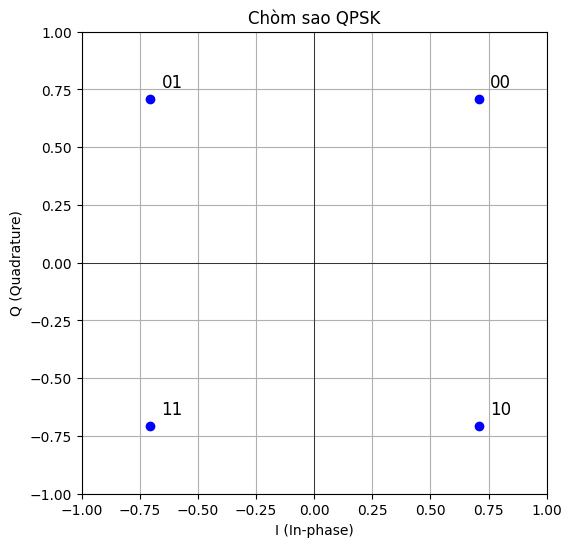

In [18]:
import matplotlib.pyplot as plt

# ==============================
# Điểm chòm sao QPSK
# ==============================
points = {
    '00': (1, 1),
    '01': (-1, 1),
    '11': (-1, -1),
    '10': (1, -1)
}

# Chuẩn hóa công suất (unit power)
for k in points:
    points[k] = (points[k][0]/2**0.5, points[k][1]/2**0.5)

# ==============================
# Vẽ chòm sao
# ==============================
plt.figure(figsize=(6,6))
for label, (I, Q) in points.items():
    plt.plot(I, Q, 'bo')
    plt.text(I+0.05, Q+0.05, label, fontsize=12)

plt.axhline(0, color='k', linewidth=0.5)
plt.axvline(0, color='k', linewidth=0.5)
plt.grid(True)
plt.title('Chòm sao QPSK')
plt.xlabel('I (In-phase)')
plt.ylabel('Q (Quadrature)')
plt.xlim(-1, 1)
plt.ylim(-1, 1)
plt.show()
